On examine la distribution es laberls pour svoir l'equilibre entre les classes a predire

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main_dir = Path("/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33")
df = pd.read_csv(main_dir / "scenario33_dev.csv", index_col=0)

N_BEAMS = 64
print(df.shape)
df[["unit1_beam", "seq_index", "time_stamp"]].head()

(3981, 19)


,unit1_beam,seq_index,time_stamp
index,,,
1,3,1,04:09:06-325991
2,2,1,04:09:06-418775
3,4,1,04:09:06-510460
4,3,1,04:09:06-601724
5,3,1,04:09:06-693246


# distribution des faisceaux et équilibre

Faisceaux présents : 63/64 | jamais utilisés : [1]
Le plus fréquent : faisceau 22 (16.3% des échantillons)
Échantillons par faisceau présent : min=2, médiane=31, max=647
Faisceaux avec moins de 10 échantillons : 9
Ratio max/min : 324
Entropie : 5.09 bits (équilibre parfait = 5.98)
Top-1 baseline triviale : 16.3%
Top-3 baseline triviale : 28.3%
Top-5 baseline triviale : 37.1%


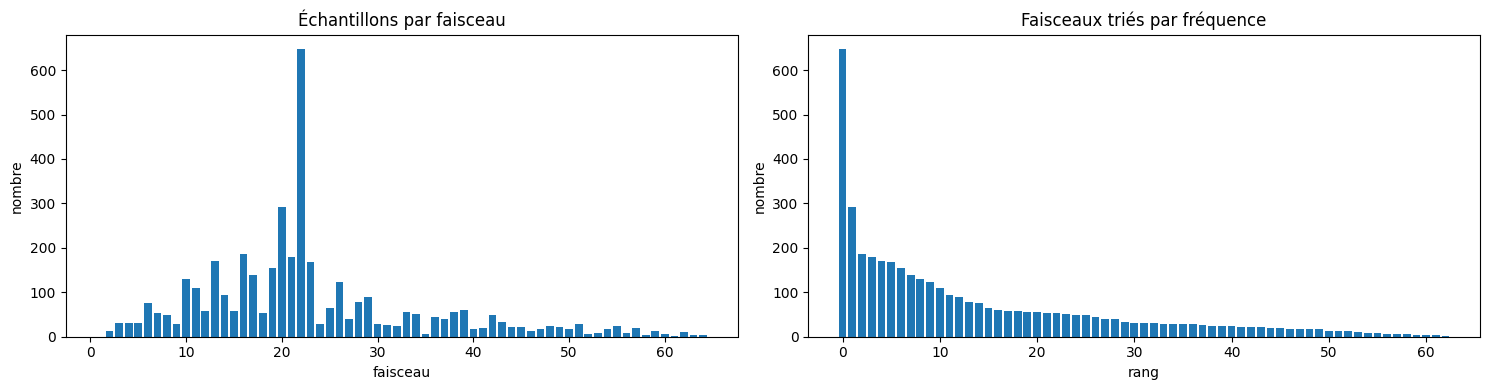

In [2]:
counts = df["unit1_beam"].value_counts().reindex(range(1, N_BEAMS + 1), fill_value=0)
freq = counts / counts.sum()
present = counts[counts > 0]
p = freq[freq > 0]

print(f"Faisceaux présents : {len(present)}/{N_BEAMS} | jamais utilisés : {list(counts[counts == 0].index)}")
print(f"Le plus fréquent : faisceau {counts.idxmax()} ({freq.max():.1%} des échantillons)")
print(f"Échantillons par faisceau présent : min={present.min()}, médiane={present.median():.0f}, max={present.max()}")
print(f"Faisceaux avec moins de 10 échantillons : {(present < 10).sum()}")
print(f"Ratio max/min : {present.max() / present.min():.0f}")

entropy = -(p * np.log2(p)).sum()
print(f"Entropie : {entropy:.2f} bits (équilibre parfait = {np.log2(len(p)):.2f})")

# Baseline triviale : toujours proposer les k faisceaux les plus fréquents
for k in (1, 3, 5):
    print(f"Top-{k} baseline triviale : {freq.nlargest(k).sum():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(counts.index, counts.values)
ax[0].set_title("Échantillons par faisceau")
ax[0].set_xlabel("faisceau"); ax[0].set_ylabel("nombre")
ax[1].bar(range(len(present)), present.sort_values(ascending=False).values)
ax[1].set_title("Faisceaux triés par fréquence")
ax[1].set_xlabel("rang"); ax[1].set_ylabel("nombre")
plt.tight_layout(); plt.show()

### Conclusions : distribution du label `unit1_beam`

- 63 faisceaux sur 64 apparaissent. Le **faisceau 1 n'est jamais le meilleur faisceau** : il n'a aucun échantillon.
- Le faisceau le plus fréquent est le **22** : 647 échantillons (16,3 %). Un faisceau typique en a 31 (médiane), le plus rare en a 2.
- 9 faisceaux ont moins de 10 échantillons. Ils seront très difficiles à apprendre.
- Entropie = 5,09 bits (maximum 5,98) : la répartition est inégale mais pas extrême.
- La masse est entre les faisceaux 8 et 30. Au-delà de 35, chaque faisceau a peu d'échantillons.

**Baseline triviale** (toujours proposer les faisceaux les plus fréquents, calculée sur tout le dataset) :
Top-1 = 16,3 %, Top-3 = 28,3 %, Top-5 = 37,1 %.
Notre modèle devra faire mieux.

**Décisions**
- Garder 64 sorties, avec le label `beam − 1` (classes de 0 à 63). Le faisceau 0 n'apparaît jamais.
- Utiliser Top-1, Top-3 et Top-5 comme métriques, pas seulement l'accuracy.
- Comparer cross-entropy simple, cross-entropy pondérée et focal loss.
- Recalculer la baseline triviale sur le train seulement.

# distribution par séquence (important, car le split se fait par séquence)

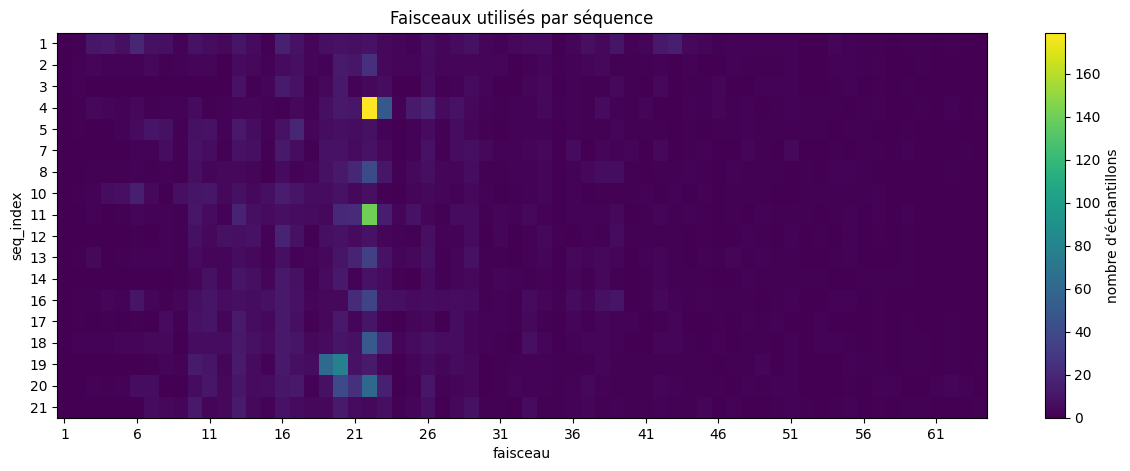

seq_index
1     56
2     50
3     35
4     55
5     48
7     43
8     49
10    46
11    49
12    42
13    48
14    44
16    51
17    43
18    49
19    48
20    50
21    47
Name: faisceaux distincts par séquence, dtype: int64


In [3]:
ct = pd.crosstab(df["seq_index"], df["unit1_beam"]).reindex(columns=range(1, N_BEAMS + 1), fill_value=0)

plt.figure(figsize=(15, 5))
plt.imshow(ct.values, aspect="auto", cmap="viridis")
plt.colorbar(label="nombre d'échantillons")
plt.yticks(range(len(ct)), ct.index)
plt.xticks(range(0, N_BEAMS, 5), range(1, N_BEAMS + 1, 5))
plt.xlabel("faisceau"); plt.ylabel("seq_index")
plt.title("Faisceaux utilisés par séquence")
plt.show()

print(ct.gt(0).sum(axis=1).rename("faisceaux distincts par séquence"))

### Conclusions : faisceaux par séquence

- Le tableau croisé compte, pour chaque séquence, le nombre d'échantillons par faisceau. 18 séquences sont présentes (les n° 6, 9 et 15 manquent).
- Chaque séquence contient entre **35 et 56 faisceaux différents** : elles couvrent toutes un large éventail de faisceaux. La séquence 3, la plus basse (35), est aussi courte (119 échantillons).
- Le pic du faisceau 22 vient surtout de quelques séquences : la 4 (environ 175) et la 11 (environ 130), soit à peu près la moitié des 647 échantillons (valeurs lues sur le graphique).
- Hypothèse à vérifier : sur ces séquences, le véhicule reste longtemps dans la même direction (vitesse proche de 0 ?).

**Conséquences pour le découpage**
- Le split se fait par séquence. Avec 18 séquences, un test de 15 % n'en contient que 2 ou 3 : le résultat dépend fortement des séquences choisies.
- Après le split, vérifier que train, validation et test ont des distributions de faisceaux comparables.
- Envisager une validation croisée par séquences pour un résultat plus fiable.

charger la matrice des puissances
python


In [3]:
pwr = pd.DataFrame({i: np.loadtxt(main_dir / f) for i, f in df["unit1_pwr_60ghz"].items()}).T
pwr.columns = range(1, N_BEAMS + 1)
print(pwr.shape)

(3981, 64)


où sont les 62 NaN ?

In [7]:
nan_mask = pwr.isna()
per_row = nan_mask.sum(axis=1)
rows_nan = per_row[per_row > 0].index

print("NaN au total :", nan_mask.sum().sum())
print("Lignes touchées :", len(rows_nan))
print("Nombre de NaN par ligne touchée :\n", per_row[per_row > 0].value_counts())
print("Faisceaux touchés :\n", nan_mask.sum()[lambda s: s > 0])
print("Séquences touchées :\n", df.loc[rows_nan, "seq_index"].value_counts())

# Le NaN est-il sur le faisceau qui sert de label ?
nan_on_label = [pd.isna(pwr.at[i, df.at[i, "unit1_beam"]]) for i in rows_nan]
print("NaN sur le faisceau du label :", sum(nan_on_label), "/", len(rows_nan))

# Le label égale-t-il l'argmax en ignorant les NaN ?
best = pwr.idxmax(axis=1)
mismatch = df.index[best != df["unit1_beam"]]
print("Lignes où label != argmax :", len(mismatch))
print("Dont lignes avec NaN :", len(set(mismatch) & set(rows_nan)))

NaN au total : 62
Lignes touchées : 38
Nombre de NaN par ligne touchée :
 1    29
2     6
9     2
3     1
Name: count, dtype: int64
Faisceaux touchés :
 7     1
8     1
9     1
11    1
13    2
14    2
15    3
16    2
17    2
18    2
19    2
20    2
21    3
25    2
26    2
27    2
31    3
36    1
40    1
47    2
48    1
49    1
52    1
55    1
56    2
57    1
59    1
60    2
61    2
62    5
63    3
64    5
dtype: int64
Séquences touchées :
 seq_index
19    6
20    5
4     4
13    4
14    3
7     3
10    2
11    2
17    2
1     1
2     1
5     1
8     1
12    1
18    1
21    1
Name: count, dtype: int64
NaN sur le faisceau du label : 38 / 38
Lignes où label != argmax : 38
Dont lignes avec NaN : 38


In [9]:
first_nan = pwr.loc[rows_nan].isna().idxmax(axis=1)
print("label == premier NaN :", (first_nan == df.loc[rows_nan, "unit1_beam"]).mean())
print(df.loc[rows_nan, "unit1_beam"].value_counts().sort_index())

label == premier NaN : 1.0
unit1_beam
7     1
9     1
11    1
13    2
15    1
21    1
25    2
26    1
27    1
31    3
36    1
40    1
47    2
49    1
52    1
55    1
56    2
57    1
59    1
60    2
61    2
62    4
63    2
64    3
Name: count, dtype: int64


In [10]:
bad_idx = rows_nan
df_clean = df.drop(index=bad_idx)
pwr_clean = pwr.drop(index=bad_idx)
print(len(df), "->", len(df_clean))

before = df["unit1_beam"].value_counts().reindex(range(1, N_BEAMS + 1), fill_value=0)
after = df_clean["unit1_beam"].value_counts().reindex(range(1, N_BEAMS + 1), fill_value=0)

cmp = pd.DataFrame({"avant": before, "après": after, "retirés": before - after})
print(cmp[cmp["retirés"] > 0])

print("Faisceaux avec 1 à 9 échantillons : avant", before.between(1, 9).sum(), "| après", after.between(1, 9).sum())
print("Faisceaux absents : avant", (before == 0).sum(), "| après", (after == 0).sum())
print("label == argmax sur les lignes propres :", (pwr_clean.idxmax(axis=1) == df_clean["unit1_beam"]).mean())

3981 -> 3943
            avant  après  retirés
unit1_beam                       
7              53     52        1
9              29     28        1
11            109    108        1
13            170    168        2
15             57     56        1
21            180    179        1
25             64     62        2
26            124    123        1
27             41     40        1
31             27     24        3
36             44     43        1
40             17     16        1
47             17     15        2
49             21     20        1
52              7      6        1
55             24     23        1
56              9      7        2
57             20     19        1
59             14     13        1
60              6      4        2
61              2      0        2
62             10      6        4
63              3      1        2
64              3      0        3
Faisceaux avec 1 à 9 échantillons : avant 9 | après 8
Faisceaux absents : avant 1 | après 3
label == ar

inspecter les 8 colonnes GPS

In [8]:
gps_extra = ["unit2_spd_over_grnd_kmph", "unit2_num_sats", "unit2_altitude", "unit2_geo_sep",
             "unit2_mode_fix_type", "unit2_pdop", "unit2_hdop", "unit2_vdop"]

summary = pd.DataFrame({
    "nan": df[gps_extra].isna().sum(),
    "distinctes": df[gps_extra].nunique(),
    "min": df[gps_extra].min(),
    "max": df[gps_extra].max(),
    "std": df[gps_extra].std(),
    "zéros": (df[gps_extra] == 0).sum(),
    "corr_beam": df[gps_extra].corrwith(df["unit1_beam"], method="spearman"),
}).round(3)
print(summary)

print(df["unit2_mode_fix_type"].value_counts(dropna=False))

# Les zéros sont-ils sur les mêmes lignes ?
q = ["unit2_mode_fix_type", "unit2_pdop", "unit2_hdop", "unit2_vdop"]
print("Lignes avec zéros partout :", (df[q] == 0).all(axis=1).sum())

                          nan  distinctes      min      max    std  zéros  \
unit2_spd_over_grnd_kmph  302        3188    0.000   21.971  6.554      1   
unit2_num_sats            302           1   12.000   12.000  0.000      0   
unit2_altitude            302        1053  354.977  356.184  0.305      0   
unit2_geo_sep             302           2  -27.750  -27.749  0.000      0   
unit2_mode_fix_type       302           2    0.000    3.000  0.389     63   
unit2_pdop                302          27    0.000    1.150  0.135     63   
unit2_hdop                302          13    0.000    0.590  0.074     63   
unit2_vdop                302          26    0.000    1.000  0.116     63   

                          corr_beam  
unit2_spd_over_grnd_kmph      0.316  
unit2_num_sats                  NaN  
unit2_altitude               -0.203  
unit2_geo_sep                -0.415  
unit2_mode_fix_type           0.004  
unit2_pdop                   -0.009  
unit2_hdop                   -0.107  
un

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


In [5]:

import pandas as pd
import numpy as np

# Statistiques de chaque séquence
seq_stats = (
    data.groupby("seq_index")
    .agg(
        n_samples=("label", "size"),
        n_beams=("label", "nunique")
    )
    .sort_index()
)

# Proportion de chaque séquence dans le dataset
seq_stats["percentage"] = (
    seq_stats["n_samples"] / len(data) * 100
).round(2)

# Nombre d'échantillons par classe dans chaque séquence
beam_distribution = pd.crosstab(
    data["seq_index"],
    data["label"]
)

print("Nombre total d'échantillons :", len(data))
print("Nombre de séquences :", data["seq_index"].nunique())
print("\nStatistiques par séquence :")
display(seq_stats)

print("\nDistribution des beams par séquence :")
display(beam_distribution)


Nombre total d'échantillons : 3943
Nombre de séquences : 18

Statistiques par séquence :


,n_samples,n_beams,percentage
seq_index,,,
1,295,56,7.48
2,167,50,4.24
3,119,35,3.02
4,395,52,10.02
5,172,47,4.36
7,170,42,4.31
8,198,49,5.02
10,186,46,4.72
11,343,49,8.70



Distribution des beams par séquence :


label,1,2,3,4,5,6,7,8,9,10,...,52,53,54,55,56,57,58,59,61,62
seq_index,,,,,,,,,,,,,,,,,,,,,
1,1,11,12,7,19,8,7,2,9,6,...,0,3,2,1,1,0,1,1,1,0
2,2,3,2,2,2,4,1,2,3,3,...,0,2,2,1,2,0,0,1,0,0
3,2,0,0,0,0,0,0,0,0,0,...,0,1,2,0,1,0,1,0,0,0
4,1,4,3,2,4,1,2,2,5,1,...,1,1,0,1,2,0,0,0,1,0
5,1,0,0,2,5,10,8,1,8,9,...,1,0,1,1,0,0,1,0,0,0
7,0,0,0,0,2,1,6,1,9,6,...,0,1,0,1,1,0,2,0,0,0
8,0,1,1,1,2,1,2,1,7,3,...,0,2,2,1,0,0,0,0,1,0
10,1,2,6,7,15,4,0,7,10,11,...,1,1,1,1,2,0,0,0,0,0
11,0,2,0,1,3,2,2,1,11,5,...,0,1,2,0,2,0,1,0,0,0


In [6]:

# Nombre d'échantillons de chaque classe dans tout le dataset
beam_counts = (
    data["label"]
    .value_counts()
    .sort_index()
    .reindex(range(64), fill_value=0)
)

beam_summary = pd.DataFrame({
    "label": range(64),
    "nombre_samples": beam_counts.values
})

beam_summary["percentage"] = (
    beam_summary["nombre_samples"] / len(data) * 100
).round(2)

display(beam_summary)

print("Classes absentes :",
      beam_summary.loc[
          beam_summary["nombre_samples"] == 0, "label"
      ].tolist())

print("Classes rares (moins de 10 échantillons) :")
display(
    beam_summary[
        (beam_summary["nombre_samples"] > 0) &
        (beam_summary["nombre_samples"] < 10)
    ]
)


,label,nombre_samples,percentage
0,0,0,0.00
1,1,13,0.33
2,2,32,0.81
3,3,31,0.79
4,4,30,0.76
...,...,...,...
59,59,4,0.10
60,60,0,0.00
61,61,6,0.15
62,62,1,0.03


Classes absentes : [0, 60, 63]
Classes rares (moins de 10 échantillons) :


,label,nombre_samples,percentage
34,34,7,0.18
51,51,6,0.15
52,52,9,0.23
55,55,7,0.18
57,57,3,0.08
59,59,4,0.10
61,61,6,0.15
62,62,1,0.03


In [8]:

# Classes rares : moins de 10 échantillons
rare_labels = (
    data["label"]
    .value_counts()
    .loc[lambda x: x < 10]
    .index
    .sort_values()
)

# Répartition des classes rares entre les séquences
rare_distribution = pd.crosstab(
    data["seq_index"],
    data["label"]
).reindex(columns=rare_labels, fill_value=0)

display(rare_distribution)

# Identifier précisément les séquences contenant chaque classe rare
for label in rare_labels:
    samples = data[data["label"] == label]

    print(
        f"Label {label} : "
        f"{len(samples)} échantillon(s), "
        f"séquence(s) : {sorted(samples['seq_index'].unique())}"
    )


label,34,51,52,55,57,59,61,62
seq_index,,,,,,,,
1,0,0,0,1,0,1,1,0
2,1,0,0,1,0,1,0,0
3,0,0,0,0,0,0,0,0
4,1,1,1,1,0,0,1,0
5,0,0,1,1,0,0,0,0
7,0,0,0,1,0,0,0,0
8,0,1,0,1,0,0,1,0
10,0,1,1,1,0,0,0,0
11,0,1,0,0,0,0,0,0


Label 34 : 7 échantillon(s), séquence(s) : [np.int64(2), np.int64(4), np.int64(12), np.int64(16), np.int64(19), np.int64(20), np.int64(21)]
Label 51 : 6 échantillon(s), séquence(s) : [np.int64(4), np.int64(8), np.int64(10), np.int64(11), np.int64(14), np.int64(21)]
Label 52 : 9 échantillon(s), séquence(s) : [np.int64(4), np.int64(5), np.int64(10), np.int64(12), np.int64(14), np.int64(17), np.int64(18)]
Label 55 : 7 échantillon(s), séquence(s) : [np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10)]
Label 57 : 3 échantillon(s), séquence(s) : [np.int64(14), np.int64(20)]
Label 59 : 4 échantillon(s), séquence(s) : [np.int64(1), np.int64(2), np.int64(19), np.int64(21)]
Label 61 : 6 échantillon(s), séquence(s) : [np.int64(1), np.int64(4), np.int64(8), np.int64(18), np.int64(20)]
Label 62 : 1 échantillon(s), séquence(s) : [np.int64(20)]


In [9]:

rare_labels = [34, 51, 52, 55, 57, 59, 61, 62]

for label in rare_labels:
    subset = data[data["label"] == label]

    print(f"\nLabel {label}")
    print("Nombre total :", len(subset))
    print("Répartition par séquence :")
    print(
        subset.groupby("seq_index")
        .size()
        .sort_index()
        .to_dict()
    )



Label 34
Nombre total : 7
Répartition par séquence :
{2: 1, 4: 1, 12: 1, 16: 1, 19: 1, 20: 1, 21: 1}

Label 51
Nombre total : 6
Répartition par séquence :
{4: 1, 8: 1, 10: 1, 11: 1, 14: 1, 21: 1}

Label 52
Nombre total : 9
Répartition par séquence :
{4: 1, 5: 1, 10: 1, 12: 1, 14: 1, 17: 2, 18: 2}

Label 55
Nombre total : 7
Répartition par séquence :
{1: 1, 2: 1, 4: 1, 5: 1, 7: 1, 8: 1, 10: 1}

Label 57
Nombre total : 3
Répartition par séquence :
{14: 1, 20: 2}

Label 59
Nombre total : 4
Répartition par séquence :
{1: 1, 2: 1, 19: 1, 21: 1}

Label 61
Nombre total : 6
Répartition par séquence :
{1: 1, 4: 1, 8: 1, 18: 1, 20: 2}

Label 62
Nombre total : 1
Répartition par séquence :
{20: 1}



## Expérience 1 — Prédiction de faisceau à partir de la distance et de l'angle GPS

### 1. Objectif

Cette première expérience vise à étudier si les informations géométriques dérivées du GPS peuvent être utilisées indépendamment pour prédire le faisceau mmWave optimal.

Les données GPS de **Unit 2 (le véhicule transmetteur mobile)** fournissent sa position géographique (latitude et longitude), tandis que Unit 1 représente la station fixe.

À partir des positions des deux unités, nous calculons deux caractéristiques décrivant la position relative du véhicule par rapport à la station :

- **Distance (`dist_m`) :** distance entre le véhicule transmetteur et la station fixe, exprimée en mètres.
- **Angle (`bearing_deg`) :** direction angulaire du véhicule par rapport à la station, exprimée en degrés.

Ces deux caractéristiques apportent des informations géométriques complémentaires :

- L'angle indique la direction dans laquelle se trouve le transmetteur par rapport à la station. Il peut ainsi contribuer à identifier les directions de faisceaux les plus pertinentes.
- La distance décrit l'éloignement entre les deux unités et peut fournir des informations utiles sur les conditions de propagation et la puissance du signal reçu.

### 2. Motivation scientifique

L'utilisation de la localisation pour faciliter l'alignement des faisceaux mmWave a déjà été étudiée dans la littérature scientifique.

Plusieurs travaux ont notamment exploré l'exploitation des informations de position pour identifier des faisceaux candidats et réduire le recours au balayage exhaustif :

1. **Va et al. (2018) — Inverse Multipath Fingerprinting for Millimeter Wave V2I Beam Alignment.** Ce travail exploite les informations de position des véhicules, notamment celles pouvant être obtenues par GPS, pour identifier les directions de faisceaux pertinentes à partir d'une base de données de signatures multipath.

2. **Rezaie et al. (2020) — Location- and Orientation-Aided Millimeter Wave Beam Selection Using Deep Learning.** Cette étude exploite la localisation et l'orientation de l'utilisateur pour sélectionner une liste restreinte de faisceaux candidats.

3. **Position-Aided Beam Prediction in the Real World: How Useful GPS Locations Actually are? (IEEE ICC 2023).** Ce travail étudie l'utilité des informations de position GPS pour la prédiction de faisceaux à partir de mesures réalisées dans des conditions réelles.

### 3. Configuration expérimentale

Le modèle utilise deux caractéristiques en entrée :

\[
X = [dist\_m,\ bearing\_deg]
\]

La variable cible correspond au faisceau optimal, converti en 64 classes numérotées de 0 à 63 :

\[
y = label = unit1\_beam - 1
\]

L'objectif est d'évaluer la capacité d'un modèle à prédire le faisceau optimal en exploitant uniquement la position géométrique relative du véhicule transmetteur par rapport à la station fixe.

### 4. Question de recherche

**Dans quelle mesure la distance et la position angulaire du véhicule transmetteur par rapport à une station fixe permettent-elles de prédire le faisceau mmWave optimal ?**

Cette première expérience constitue une référence fondée sur les informations GPS. Ses performances seront ensuite comparées à celles obtenues avec les autres modalités de perception et avec leur fusion.

### 5. Références bibliographiques

- Va et al. (2018) : [Inverse Multipath Fingerprinting for Millimeter Wave V2I Beam Alignment](https://rosap.ntl.bts.gov/view/dot/32606/dot_32606_DS1.pdf)
- Rezaie et al. (2020) : [Location- and Orientation-Aided Millimeter Wave Beam Selection Using Deep Learning](https://doi.org/10.1109/ICC40277.2020.9149272)
- IEEE ICC (2023) : [Position-Aided Beam Prediction in the Real World: How Useful GPS Locations Actually are?](https://doi.org/10.1109/ICC45041.2023.10278998)


In [2]:
import re
import numpy as np
import pandas as pd
from pathlib import Path

main_dir = Path("/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33")
df = pd.read_csv(main_dir / "scenario33_dev.csv", index_col=0)
print(df.shape)   # attendu : (3981, ...)

(3981, 19)


In [3]:
def read_vec(path):
    with open(path) as f:
        return [float(line) for line in f if line.strip()]

pwr = pd.DataFrame({i: read_vec(main_dir / f) for i, f in df["unit1_pwr_60ghz"].items()}).T

rows_nan = pwr.index[pwr.isna().any(axis=1)]
print("lignes avec NaN :", len(rows_nan))          # attendu : 38

df_clean = df.drop(index=rows_nan)
print("df_clean :", df_clean.shape)                # attendu : (3943, ...)

# Liste commune pour l'équipe (le fichier lignes_retirees.csv du contrat)
pd.Series(rows_nan, name="index").to_csv("/kaggle/working/lignes_retirees.csv", index=False)

lignes avec NaN : 38
df_clean : (3943, 19)


on traite les colonne et les transforme en distance et angle pour voir comment le model s'entraine

In [4]:
import re
import numpy as np
import pandas as pd

def file_index(p):
    return int(re.findall(r"\d+", p.stem)[-1])   # GPS_location_12.txt -> 12

# Position fixe de la station (unit1)
u1_lat, u1_lon = np.loadtxt(main_dir / "unit1" / "GPS_data" / "gps_location.txt")

# Position de la voiture (unit2), un fichier par échantillon
rows = []
for p in (main_dir / "unit2" / "GPS_data").iterdir():
    lat, lon = np.loadtxt(p)
    rows.append((file_index(p), lat, lon))
gps2 = pd.DataFrame(rows, columns=["index", "lat", "lon"]).set_index("index").sort_index()

# Degrés -> mètres par rapport à la station, puis distance et angle
R = 6371000
gps2["x_m"] = np.deg2rad(gps2["lon"] - u1_lon) * R * np.cos(np.deg2rad(u1_lat))  # est
gps2["y_m"] = np.deg2rad(gps2["lat"] - u1_lat) * R                                 # nord
gps2["dist_m"] = np.hypot(gps2["x_m"], gps2["y_m"])
gps2["bearing_deg"] = np.degrees(np.arctan2(gps2["x_m"], gps2["y_m"]))             # 0 = nord, + = est

# Table de travail : seulement les lignes propres (3 943)
data = df_clean[["seq_index", "unit1_beam"]].join(gps2[["dist_m", "bearing_deg"]])
data["label"] = data["unit1_beam"] - 1     # 0..63 pour l'entraînement
print(data.shape, data.isna().sum().to_dict())
data.head()

(3943, 5) {'seq_index': 0, 'unit1_beam': 0, 'dist_m': 0, 'bearing_deg': 0, 'label': 0}


,seq_index,unit1_beam,dist_m,bearing_deg,label
index,,,,,
1,1,3,49.377708,-8.858732,2
2,1,2,49.339846,-8.605174,1
3,1,4,49.303970,-8.356325,3
4,1,3,49.264415,-8.115333,2
5,1,3,49.225615,-7.879247,2


on etudie encore la correlation de ces deux colonnes avec le label:

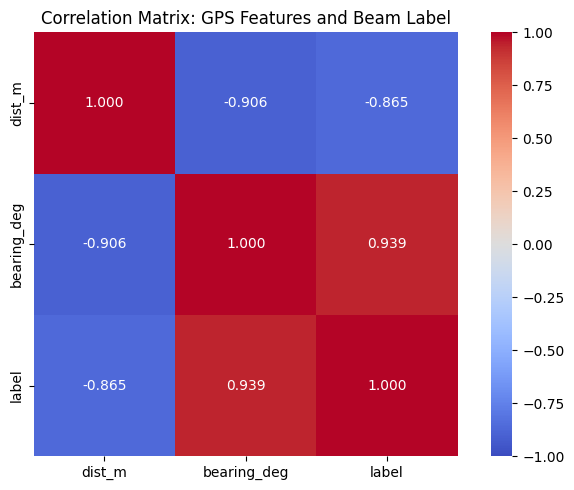

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Corrélation entre les deux caractéristiques GPS et le label
corr = data[["dist_m", "bearing_deg", "label"]].corr(method="pearson")

# Affichage de la matrice de corrélation
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix: GPS Features and Beam Label")
plt.tight_layout()
plt.show()


### Analyse de la matrice de corrélation

La matrice de corrélation de Pearson révèle une forte corrélation négative entre `dist_m` et `bearing_deg` (-0.906), ce qui indique que ces deux caractéristiques géométriques évoluent ensemble dans notre dataset.

Elle montre également de fortes corrélations entre les caractéristiques GPS et le label du beam : -0.865 pour la distance et +0.939 pour le bearing.

Cependant, ces résultats doivent être interprétés avec prudence, car `label` est une variable catégorielle représentant l'une des 64 classes de beams (0–63), et non une mesure numérique continue.

Par conséquent, la corrélation de Pearson n'est pas adaptée pour évaluer correctement la relation statistique entre les caractéristiques GPS et le beam optimal. Une méthode statistique plus appropriée est nécessaire.

### Analyse par information mutuelle (Mutual Information)

**Qu'est-ce que l'information mutuelle mesure ?**

L'information mutuelle (MI) est une mesure statistique qui quantifie la quantité d'information qu'une variable apporte sur une autre. Contrairement à la corrélation de Pearson, elle permet de détecter des dépendances statistiques linéaires et non linéaires.

Dans notre expérience, la MI mesure dans quelle mesure chaque caractéristique GPS (`dist_m` et `bearing_deg`) apporte de l'information sur la classe du beam optimal (`label`).


In [7]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

X = data[["dist_m", "bearing_deg"]]
y = data["label"]

mi = mutual_info_classif(
    X,
    y,
    random_state=42,
    n_neighbors=5
)

mi_results = pd.DataFrame({
    "Feature": X.columns,
    "Mutual Information": mi
}).sort_values(
    "Mutual Information",
    ascending=False
)

display(mi_results)

,Feature,Mutual Information
1,bearing_deg,2.101539
0,dist_m,1.442854


**Interprétation des résultats :**

- `bearing_deg` apporte davantage d'information sur la classe du beam optimal que `dist_m` dans cette analyse.
- `dist_m` apporte également de l'information sur la classe du beam.
- Les deux caractéristiques peuvent contribuer à la prédiction du beam, mais une partie de leur information peut être redondante, puisqu'elles présentent une forte corrélation entre elles.

**Propriétés et limites de l'information mutuelle :**

- L'information mutuelle est toujours positive ou nulle.
- Une valeur égale à 0 indique une indépendance statistique entre les variables dans la population.
- Une valeur plus élevée indique une dépendance statistique plus importante.
- Avec `mutual_info_classif`, les valeurs sont exprimées en nats par défaut.
- L'information mutuelle n'a pas de borne supérieure fixe.
- Elle ne permet pas d'établir une relation de causalité ni de garantir de bonnes performances de classification.
- Les valeurs estimées dépendent du dataset et des paramètres utilisés, notamment `n_neighbors`.

**Conclusion :**

Le bearing semble être la caractéristique GPS individuelle la plus informative pour identifier le beam optimal dans notre dataset. Cependant, des expériences de classification seront nécessaires pour déterminer si la combinaison de la distance et du bearing améliore réellement les performances de prédiction du beam.

In [10]:

# Séquences choisies pour chaque groupe
train_sequences = [1, 2, 4, 5, 8, 10, 12, 14, 17, 18, 20, 21]
val_sequences   = [3, 7, 11]
test_sequences  = [13, 16, 19]

# Affecter un groupe à chaque échantillon
split = data[["seq_index"]].copy()

split["groupe"] = np.select(
    [
        split["seq_index"].isin(train_sequences),
        split["seq_index"].isin(val_sequences),
        split["seq_index"].isin(test_sequences)
    ],
    ["train", "val", "test"],
    default="unassigned"
)

# Ajouter l'index des échantillons
split.insert(0, "index", data.index)

# Vérification
print("Répartition des groupes :")
display(split["groupe"].value_counts())

print("\nRépartition en pourcentage :")
display(
    (split["groupe"].value_counts(normalize=True) * 100).round(2)
)

print("\nAperçu du split :")
display(split.head())

# Sauvegarder le fichier commun
split.to_csv("split.csv", index=False)


Répartition des groupes :


groupe
train    2574
test      737
val       632
Name: count, dtype: int64


Répartition en pourcentage :


groupe
train    65.28
test     18.69
val      16.03
Name: proportion, dtype: float64


Aperçu du split :


,index,seq_index,groupe
index,,,
1,1,1,train
2,2,1,train
3,3,1,train
4,4,1,train
5,5,1,train


In [11]:

# Vérifier les séquences présentes dans chaque groupe
for group in ["train", "val", "test"]:
    sequences = sorted(
        split.loc[split["groupe"] == group, "seq_index"].unique()
    )
    print(f"{group}: {sequences}")

# Vérifier les séquences non affectées
print("\nÉchantillons non affectés :",
      (split["groupe"] == "unassigned").sum())


train: [np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(17), np.int64(18), np.int64(20), np.int64(21)]
val: [np.int64(3), np.int64(7), np.int64(11)]
test: [np.int64(13), np.int64(16), np.int64(19)]

Échantillons non affectés : 0


In [12]:

# Vérification complète du split

print("Nombre d'échantillons non affectés :",
      (split["groupe"] == "unassigned").sum())

print("\nNombre de séquences par groupe :")
display(
    split.groupby("groupe")["seq_index"].nunique()
)

# Vérifier la présence des classes dans chaque groupe
split_analysis = split.join(data["label"])

for group in ["train", "val", "test"]:
    subset = split_analysis[split_analysis["groupe"] == group]

    present = sorted(subset["label"].unique())
    absent = sorted(set(range(64)) - set(present))

    print(f"\n--- {group.upper()} ---")
    print("Échantillons :", len(subset))
    print("Classes présentes :", len(present))
    print("Classes absentes :", absent)



Nombre d'échantillons non affectés : 0

Nombre de séquences par groupe :


groupe
test      3
train    12
val       3
Name: seq_index, dtype: int64


--- TRAIN ---
Échantillons : 2574
Classes présentes : 61
Classes absentes : [0, 60, 63]

--- VAL ---
Échantillons : 632
Classes présentes : 54
Classes absentes : [0, 3, 34, 52, 57, 59, 60, 61, 62, 63]

--- TEST ---
Échantillons : 737
Classes présentes : 55
Classes absentes : [0, 51, 52, 55, 57, 60, 61, 62, 63]


## SVM 

## entrainement

In [13]:

import pandas as pd
import numpy as np

# 1. Charger le split enregistré
split_df = pd.read_csv("split.csv")

# Utiliser l'identifiant de l'échantillon comme index
split_df = split_df.set_index("index")

# 2. Vérifier que les index correspondent
assert data.index.is_unique, "Les index de data ne sont pas uniques"
assert split_df.index.is_unique, "Les index du split ne sont pas uniques"

assert set(data.index) == set(split_df.index), (
    "Les identifiants de data et split.csv ne correspondent pas"
)

# 3. Associer le groupe à chaque échantillon
model_data = data.join(split_df[["groupe"]])

# 4. Définir les variables d'entrée et la cible
X = model_data[["dist_m", "bearing_deg"]]
y = model_data["label"]

# 5. Construire les trois groupes
train_mask = model_data["groupe"] == "train"
val_mask   = model_data["groupe"] == "val"
test_mask  = model_data["groupe"] == "test"

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val     = X[val_mask], y[val_mask]
X_test, y_test   = X[test_mask], y[test_mask]

# 6. Vérifier les dimensions
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nNombre de classes dans le train :", y_train.nunique())
print("Classes apprises :", sorted(y_train.unique()))


Train : (2574, 2) (2574,)
Validation : (632, 2) (632,)
Test : (737, 2) (737,)

Nombre de classes dans le train : 61
Classes apprises : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(61), np.int64(62)]


In [14]:

from sklearn.preprocessing import StandardScaler

# Créer le scaler
scaler = StandardScaler()

# Apprendre les paramètres uniquement sur le train
X_train_scaled = scaler.fit_transform(X_train)

# Appliquer la même transformation à validation et test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Moyennes calculées sur le train :", scaler.mean_)
print("Écarts-types calculés sur le train :", scaler.scale_)

print("\nDimensions après standardisation :")
print("Train :", X_train_scaled.shape)
print("Validation :", X_val_scaled.shape)
print("Test :", X_test_scaled.shape)


Moyennes calculées sur le train : [35.9181345  23.75795008]
Écarts-types calculés sur le train : [12.53091924 21.28139769]

Dimensions après standardisation :
Train : (2574, 2)
Validation : (632, 2)
Test : (737, 2)


In [15]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Créer le modèle SVM
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    decision_function_shape="ovr"
)

# Entraîner le modèle
svm_model.fit(X_train_scaled, y_train)

print("SVM entraîné avec succès !")
print("Nombre de classes apprises :", len(svm_model.classes_))
print("Classes apprises :", svm_model.classes_)


SVM entraîné avec succès !
Nombre de classes apprises : 61
Classes apprises : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 61 62]


In [16]:

# Prédictions sur la validation
y_val_pred = svm_model.predict(X_val_scaled)

# Calcul du Top-1
val_top1 = accuracy_score(y_val, y_val_pred)

print("Résultats du SVM sur la validation")
print("-----------------------------------")
print(f"Top-1 Accuracy : {val_top1 * 100:.2f}%")


Résultats du SVM sur la validation
-----------------------------------
Top-1 Accuracy : 52.85%


In [17]:

from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Valeurs à tester
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}

# SVM RBF
svm = SVC(kernel="rbf")

# Recherche des meilleurs paramètres
grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Entraînement sur le train uniquement
grid_search.fit(X_train_scaled, y_train)

print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleure accuracy CV :", 
      round(grid_search.best_score_ * 100, 2), "%")

# Évaluation du meilleur modèle sur la validation
best_svm = grid_search.best_estimator_

y_val_best = best_svm.predict(X_val_scaled)

best_val_accuracy = accuracy_score(y_val, y_val_best)

print("\nRésultat sur la validation :")
print(f"Top-1 : {best_val_accuracy * 100:.2f}%")


Fitting 3 folds for each of 16 candidates, totalling 48 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(


Meilleurs paramètres : {'C': 10, 'gamma': 1}
Meilleure accuracy CV : 46.5 %

Résultat sur la validation :
Top-1 : 56.65%


In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, GroupKFold, ParameterGrid
from sklearn.metrics import accuracy_score

# ==========================================
# 1. Définir les paramètres à tester
# ==========================================

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}

# ==========================================
# 2. Validation croisée par séquence
# ==========================================

# Identifiant de séquence pour chaque échantillon du train
groups_train = model_data.loc[train_mask, "seq_index"].values

# 12 séquences dans notre train : 3 folds
group_cv = GroupKFold(n_splits=3)

svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="accuracy",
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# Entraînement avec les groupes
grid_search.fit(
    X_train_scaled,
    y_train,
    groups=groups_train
)

# ==========================================
# 3. Récupérer les résultats de la CV
# ==========================================

cv_results = pd.DataFrame(grid_search.cv_results_)

results = cv_results[[
    "param_C",
    "param_gamma",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].copy()

results.columns = [
    "C",
    "gamma",
    "train_accuracy_cv",
    "cv_accuracy",
    "cv_std"
]

# ==========================================
# 4. Évaluer chaque combinaison sur la validation fixe
# ==========================================

val_scores = []
train_scores = []

for params in ParameterGrid(param_grid):

    model = SVC(
        kernel="rbf",
        C=params["C"],
        gamma=params["gamma"]
    )

    model.fit(X_train_scaled, y_train)

    # Accuracy sur train
    train_pred = model.predict(X_train_scaled)
    train_acc = accuracy_score(y_train, train_pred)

    # Accuracy sur validation
    val_pred = model.predict(X_val_scaled)
    val_acc = accuracy_score(y_val, val_pred)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

results["train_accuracy"] = train_scores
results["val_accuracy"] = val_scores

# Pourcentage
score_columns = [
    "train_accuracy_cv",
    "cv_accuracy",
    "cv_std",
    "train_accuracy",
    "val_accuracy"
]

results[score_columns] = results[score_columns] * 100

# Trier par accuracy CV décroissante
results = results.sort_values(
    by="cv_accuracy",
    ascending=False
).reset_index(drop=True)

# ==========================================
# 5. Afficher et sauvegarder les résultats
# ==========================================

display(results.round(2))

results.to_csv("svm_grid_search_results.csv", index=False)

print("Résultats sauvegardés dans svm_grid_search_results.csv")

# Meilleure combinaison selon la CV groupée
print("\nMeilleurs paramètres selon la CV groupée :")
print(grid_search.best_params_)

print(
    "Meilleure accuracy CV :",
    round(grid_search.best_score_ * 100, 2),
    "%"
)

# Modèle final sélectionné par la CV
best_svm = grid_search.best_estimator_


,C,gamma,train_accuracy_cv,cv_accuracy,cv_std,train_accuracy,val_accuracy
0,100.0,1,53.84,46.75,2.83,51.94,57.75
1,100.0,scale,52.97,46.40,2.65,50.97,57.44
2,10.0,1,51.57,46.25,2.68,50.70,56.65
3,100.0,0.1,50.84,45.93,2.48,50.35,55.85
4,10.0,scale,49.75,45.39,2.52,50.08,55.85
5,10.0,0.1,45.59,42.48,3.45,46.39,53.32
6,1.0,1,45.50,42.12,3.38,46.35,53.48
7,100.0,0.01,44.83,41.86,4.41,45.49,53.96
8,1.0,scale,42.89,39.62,4.15,44.13,52.85
9,1.0,0.1,31.58,28.17,5.87,32.75,43.83


Résultats sauvegardés dans svm_grid_search_results.csv

Meilleurs paramètres selon la CV groupée :
{'C': 100, 'gamma': 1}
Meilleure accuracy CV : 46.75 %


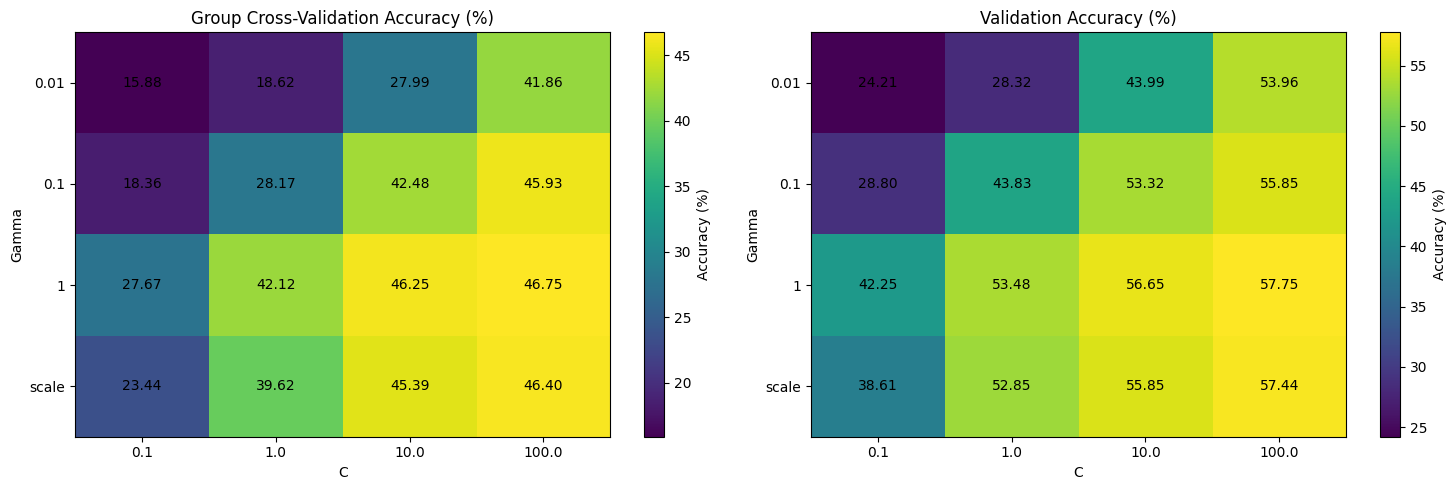

In [22]:

# Préparer les matrices pour les graphiques
cv_matrix = results.pivot(
    index="gamma",
    columns="C",
    values="cv_accuracy"
)

val_matrix = results.pivot(
    index="gamma",
    columns="C",
    values="val_accuracy"
)

# Créer les deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, matrix, title in [
    (axes[0], cv_matrix, "Group Cross-Validation Accuracy (%)"),
    (axes[1], val_matrix, "Validation Accuracy (%)")
]:

    im = ax.imshow(matrix.values, aspect="auto")

    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns)

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index)

    ax.set_xlabel("C")
    ax.set_ylabel("Gamma")
    ax.set_title(title)

    # Afficher les valeurs dans les cases
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(
                j, i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    fig.colorbar(im, ax=ax, label="Accuracy (%)")

plt.tight_layout()
plt.show()


In [23]:

from sklearn.metrics import accuracy_score
import pandas as pd

# Prédictions sur la validation fixe
y_val_best = best_svm.predict(X_val_scaled)

# Construire un tableau avec les vraies et fausses prédictions
val_analysis = pd.DataFrame({
    "seq_index": model_data.loc[val_mask, "seq_index"].values,
    "y_true": y_val.values,
    "y_pred": y_val_best
})

val_analysis["correct"] = (
    val_analysis["y_true"] == val_analysis["y_pred"]
)

# Accuracy pour chaque séquence
sequence_performance = (
    val_analysis.groupby("seq_index")
    .agg(
        n_samples=("correct", "size"),
        correct_predictions=("correct", "sum"),
        accuracy=("correct", "mean")
    )
)

sequence_performance["accuracy"] *= 100

display(sequence_performance.round(2))

print(
    "\nAccuracy globale :",
    round(accuracy_score(y_val, y_val_best) * 100, 2),
    "%"
)


,n_samples,correct_predictions,accuracy
seq_index,,,
3,119,66,55.46
7,170,96,56.47
11,343,203,59.18



Accuracy globale : 57.75 %


In [24]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
import pandas as pd

# 1. Pipeline : normalisation + SVM
minmax_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("svm", SVC(kernel="rbf"))
])

# 2. Paramètres à tester
param_grid_minmax = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1]
}

# 3. Validation croisée par séquence
groups_train = model_data.loc[
    train_mask, "seq_index"
].values

group_cv = GroupKFold(n_splits=3)

# 4. Grid Search
minmax_search = GridSearchCV(
    estimator=minmax_pipeline,
    param_grid=param_grid_minmax,
    scoring="accuracy",
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

minmax_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

# 5. Meilleur modèle
best_minmax_svm = minmax_search.best_estimator_

print("Meilleurs paramètres MinMax :")
print(minmax_search.best_params_)

print(
    "Meilleure accuracy CV :",
    round(minmax_search.best_score_ * 100, 2),
    "%"
)

# 6. Évaluation sur la validation fixe
y_val_minmax = best_minmax_svm.predict(X_val)

minmax_val_accuracy = accuracy_score(
    y_val, y_val_minmax
)

print(
    "\nTop-1 Validation MinMax :",
    round(minmax_val_accuracy * 100, 2),
    "%"
)


Meilleurs paramètres MinMax :
{'svm__C': 100, 'svm__gamma': 'scale'}
Meilleure accuracy CV : 46.58 %

Top-1 Validation MinMax : 55.54 %


In [25]:

# Résultats StandardScaler
standard_cv = grid_search.best_score_ * 100

standard_val = accuracy_score(
    y_val,
    best_svm.predict(X_val_scaled)
) * 100

# Résultats MinMaxScaler
minmax_cv = minmax_search.best_score_ * 100
minmax_val = minmax_val_accuracy * 100

comparison = pd.DataFrame({
    "Scaler": ["StandardScaler", "MinMaxScaler"],
    "Best_C": [
        grid_search.best_params_["C"],
        minmax_search.best_params_["svm__C"]
    ],
    "Best_gamma": [
        grid_search.best_params_["gamma"],
        minmax_search.best_params_["svm__gamma"]
    ],
    "CV_accuracy": [standard_cv, minmax_cv],
    "Validation_accuracy": [standard_val, minmax_val]
})

display(comparison.round(2))


,Scaler,Best_C,Best_gamma,CV_accuracy,Validation_accuracy
0,StandardScaler,100,1,46.75,57.75
1,MinMaxScaler,100,scale,46.58,55.54


FCNN

In [26]:

import numpy as np
import pandas as pd

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import accuracy_score

# ==========================================
# 1. Définir le FCNN
# ==========================================

fcnn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        activation="relu",
        solver="adam",
        max_iter=1500,
        early_stopping=False,
        random_state=42
    ))
])

# ==========================================
# 2. Hyperparamètres à tester
# ==========================================

param_grid_fcnn = {
    "mlp__hidden_layer_sizes": [
        (64, 32),
        (128, 64)
    ],
    "mlp__alpha": [
        0.0001,
        0.001
    ],
    "mlp__learning_rate_init": [
        0.001
    ]
}

# ==========================================
# 3. Validation croisée par séquence
# ==========================================

groups_train = model_data.loc[
    train_mask, "seq_index"
].values

group_cv = GroupKFold(n_splits=3)

fcnn_search = GridSearchCV(
    estimator=fcnn_pipeline,
    param_grid=param_grid_fcnn,
    scoring="accuracy",
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# ==========================================
# 4. Entraîner et comparer les configurations
# ==========================================

fcnn_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

# Meilleur modèle selon la CV groupée
best_fcnn = fcnn_search.best_estimator_

print("Meilleurs paramètres FCNN :")
print(fcnn_search.best_params_)

print(
    "\nMeilleure accuracy CV :",
    round(fcnn_search.best_score_ * 100, 2),
    "%"
)


Meilleurs paramètres FCNN :
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': 0.001}

Meilleure accuracy CV : 46.16 %


In [27]:

from sklearn.metrics import accuracy_score

# Probabilités prédites pour chaque classe
y_val_proba = best_fcnn.predict_proba(X_val)

# Classes effectivement apprises
fcnn_classes = best_fcnn.named_steps["mlp"].classes_

# Top-1
y_val_pred = fcnn_classes[
    np.argmax(y_val_proba, axis=1)
]

top1 = accuracy_score(y_val, y_val_pred)

# Fonction de calcul Top-K
def calculate_top_k(y_true, probabilities, classes, k):

    # Indices des k scores les plus élevés
    top_k_indices = np.argsort(
        probabilities, axis=1
    )[:, -k:]

    # Conversion des indices en labels
    top_k_labels = classes[top_k_indices]

    # Vérifier si le vrai label figure parmi les k prédictions
    correct = [
        true_label in predicted_labels
        for true_label, predicted_labels
        in zip(y_true, top_k_labels)
    ]

    return np.mean(correct)

top3 = calculate_top_k(
    y_val, y_val_proba, fcnn_classes, 3
)

top5 = calculate_top_k(
    y_val, y_val_proba, fcnn_classes, 5
)

print("Résultats FCNN sur la validation")
print("--------------------------------")
print(f"Top-1 : {top1 * 100:.2f}%")
print(f"Top-3 : {top3 * 100:.2f}%")
print(f"Top-5 : {top5 * 100:.2f}%")


Résultats FCNN sur la validation
--------------------------------
Top-1 : 56.65%
Top-3 : 88.13%
Top-5 : 97.47%


In [28]:

fcnn_cv_results = pd.DataFrame(fcnn_search.cv_results_)

fcnn_results = fcnn_cv_results[[
    "param_mlp__hidden_layer_sizes",
    "param_mlp__alpha",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].copy()

fcnn_results.columns = [
    "architecture",
    "alpha",
    "train_accuracy_cv",
    "cv_accuracy",
    "cv_std"
]

# Convertir en pourcentage
score_cols = [
    "train_accuracy_cv",
    "cv_accuracy",
    "cv_std"
]

fcnn_results[score_cols] *= 100

fcnn_results = fcnn_results.sort_values(
    "cv_accuracy",
    ascending=False
).reset_index(drop=True)

display(fcnn_results.round(2))

fcnn_results.to_csv(
    "fcnn_grid_search_results.csv",
    index=False
)

print("Résultats sauvegardés : fcnn_grid_search_results.csv")


,architecture,alpha,train_accuracy_cv,cv_accuracy,cv_std
0,"(128, 64)",0.0,51.84,46.16,3.27
1,"(128, 64)",0.0,51.88,46.12,3.32
2,"(64, 32)",0.0,51.63,46.10,2.87
3,"(64, 32)",0.0,51.57,46.03,2.63


Résultats sauvegardés : fcnn_grid_search_results.csv


In [30]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

# ==================================================
# 1. Préparation des données
# ==================================================

features = ["dist_m", "bearing_deg"]

X = model_data[features]
y = model_data["label"]
groups = model_data["seq_index"]

train_mask = model_data["groupe"] == "train"
val_mask = model_data["groupe"] == "val"

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
groups_train = groups.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

# ==================================================
# 2. Pipeline KNN
# ==================================================

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# ==================================================
# 3. Hyperparamètres à tester
# ==================================================

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

# p=1 : distance Manhattan
# p=2 : distance euclidienne

# ==================================================
# 4. Validation croisée par séquence
# ==================================================

group_cv = GroupKFold(n_splits=3)

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=group_cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_knn.fit(
    X_train,
    y_train,
    groups=groups_train
)

# ==================================================
# 5. Meilleurs résultats de la recherche
# ==================================================

best_knn = grid_knn.best_estimator_

print("===== MEILLEUR KNN =====")
print("Meilleurs paramètres :", grid_knn.best_params_)
print(f"Meilleure accuracy CV : {grid_knn.best_score_ * 100:.2f}%")

# ==================================================
# 6. Évaluation sur validation
# ==================================================

y_pred = best_knn.predict(X_val)
y_proba = best_knn.predict_proba(X_val)

classes = best_knn.named_steps["knn"].classes_

def calculate_top_k(y_true, y_scores, classes, k):
    top_k_indices = np.argsort(y_scores, axis=1)[:, -k:]
    top_k_classes = classes[top_k_indices]

    correct = [
        true_label in predicted_labels
        for true_label, predicted_labels in zip(y_true, top_k_classes)
    ]

    return np.mean(correct) * 100

top1 = np.mean(y_pred == y_val.to_numpy()) * 100
top3 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 3)
top5 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 5)

print("\n===== KNN : RÉSULTATS VALIDATION =====")
print(f"Top-1 : {top1:.2f}%")
print(f"Top-3 : {top3:.2f}%")
print(f"Top-5 : {top5:.2f}%")

# ==================================================
# 7. Sauvegarder les résultats de Grid Search
# ==================================================

knn_results = pd.DataFrame(grid_knn.cv_results_)
knn_results.to_csv("knn_grid_search_results.csv", index=False)

print("\nRésultats sauvegardés dans knn_grid_search_results.csv")


Fitting 3 folds for each of 28 candidates, totalling 84 fits
===== MEILLEUR KNN =====
Meilleurs paramètres : {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'uniform'}
Meilleure accuracy CV : 47.01%

===== KNN : RÉSULTATS VALIDATION =====
Top-1 : 54.91%
Top-3 : 87.03%
Top-5 : 93.51%

Résultats sauvegardés dans knn_grid_search_results.csv


In [32]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

# ==================================================
# 1. Préparation des données
# ==================================================

features = ["dist_m", "bearing_deg"]

X = model_data[features]
y = model_data["label"]
groups = model_data["seq_index"]

train_mask = model_data["groupe"] == "train"
val_mask = model_data["groupe"] == "val"

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
groups_train = groups.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

# ==================================================
# 2. Pipeline FCNN + MinMaxScaler
# ==================================================

fcnn_minmax_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("mlp", MLPClassifier(
        activation="relu",
        solver="adam",
        max_iter=1500,
        early_stopping=False,
        random_state=42
    ))
])

# ==================================================
# 3. Grille des hyperparamètres
# ==================================================

param_grid_fcnn = {
    "mlp__hidden_layer_sizes": [(64, 32), (128, 64)],
    "mlp__alpha": [0.0001, 0.001],
    "mlp__learning_rate_init": [0.001]
}

# ==================================================
# 4. Validation croisée GroupKFold
# ==================================================

group_cv = GroupKFold(n_splits=3)

grid_fcnn_minmax = GridSearchCV(
    estimator=fcnn_minmax_pipeline,
    param_grid=param_grid_fcnn,
    cv=group_cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_fcnn_minmax.fit(
    X_train,
    y_train,
    groups=groups_train
)

# ==================================================
# 5. Meilleur modèle
# ==================================================

best_fcnn_minmax = grid_fcnn_minmax.best_estimator_

print("===== MEILLEUR FCNN - MINMAX SCALER =====")
print("Meilleurs paramètres :", grid_fcnn_minmax.best_params_)
print(
    f"Meilleure accuracy CV : "
    f"{grid_fcnn_minmax.best_score_ * 100:.2f}%"
)

# ==================================================
# 6. Évaluation sur Validation
# ==================================================

y_pred = best_fcnn_minmax.predict(X_val)
y_proba = best_fcnn_minmax.predict_proba(X_val)

classes = best_fcnn_minmax.named_steps["mlp"].classes_

def calculate_top_k(y_true, y_scores, classes, k):
    top_k_indices = np.argsort(y_scores, axis=1)[:, -k:]
    top_k_classes = classes[top_k_indices]

    correct = [
        true_label in predicted_labels
        for true_label, predicted_labels in zip(y_true, top_k_classes)
    ]

    return np.mean(correct) * 100

top1 = np.mean(y_pred == y_val.to_numpy()) * 100
top3 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 3)
top5 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 5)

print("\n===== FCNN MINMAX : RÉSULTATS VALIDATION =====")
print(f"Top-1 : {top1:.2f}%")
print(f"Top-3 : {top3:.2f}%")
print(f"Top-5 : {top5:.2f}%")

# ==================================================
# 7. Sauvegarde des résultats
# ==================================================

fcnn_minmax_results = pd.DataFrame(
    grid_fcnn_minmax.cv_results_
)

fcnn_minmax_results.to_csv(
    "fcnn_minmax_grid_search_results.csv",
    index=False
)

print("\nRésultats sauvegardés.")


Fitting 3 folds for each of 4 candidates, totalling 12 fits
===== MEILLEUR FCNN - MINMAX SCALER =====
Meilleurs paramètres : {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': 0.001}
Meilleure accuracy CV : 46.45%

===== FCNN MINMAX : RÉSULTATS VALIDATION =====
Top-1 : 54.59%
Top-3 : 88.13%
Top-5 : 97.15%

Résultats sauvegardés.


### KNN

In [29]:

import numpy as np
from sklearn.metrics import accuracy_score

# Scores de décision du SVM sur la validation
svm_scores = best_svm.decision_function(X_val_scaled)

# Classes apprises par le SVM
svm_classes = best_svm.classes_

# Fonction Top-K
def calculate_top_k(y_true, scores, classes, k):

    top_k_indices = np.argsort(scores, axis=1)[:, -k:]
    top_k_labels = classes[top_k_indices]

    correct = [
        true_label in predicted_labels
        for true_label, predicted_labels in zip(y_true, top_k_labels)
    ]

    return np.mean(correct)

# Calcul des métriques
svm_top1 = accuracy_score(
    y_val,
    best_svm.predict(X_val_scaled)
)

svm_top3 = calculate_top_k(
    y_val, svm_scores, svm_classes, 3
)

svm_top5 = calculate_top_k(
    y_val, svm_scores, svm_classes, 5
)

print("Résultats SVM sur la validation")
print("--------------------------------")
print(f"Top-1 : {svm_top1 * 100:.2f}%")
print(f"Top-3 : {svm_top3 * 100:.2f}%")
print(f"Top-5 : {svm_top5 * 100:.2f}%")


Résultats SVM sur la validation
--------------------------------
Top-1 : 57.75%
Top-3 : 88.13%
Top-5 : 97.78%


In [31]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

# ==================================================
# 1. Préparation des données
# ==================================================

features = ["dist_m", "bearing_deg"]

X = model_data[features]
y = model_data["label"]
groups = model_data["seq_index"]

train_mask = model_data["groupe"] == "train"
val_mask = model_data["groupe"] == "val"

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
groups_train = groups.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

# ==================================================
# 2. Modèle Random Forest
# ==================================================

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# ==================================================
# 3. Hyperparamètres à tester
# ==================================================

param_grid_rf = {
    "n_estimators": [200, 400],
    "max_depth": [None, 20, 40],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

# ==================================================
# 4. Validation croisée par séquence
# ==================================================

group_cv = GroupKFold(n_splits=3)

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=group_cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_rf.fit(
    X_train,
    y_train,
    groups=groups_train
)

# ==================================================
# 5. Meilleurs résultats
# ==================================================

best_rf = grid_rf.best_estimator_

print("===== MEILLEUR RANDOM FOREST =====")
print("Meilleurs paramètres :", grid_rf.best_params_)
print(f"Meilleure accuracy CV : {grid_rf.best_score_ * 100:.2f}%")

# ==================================================
# 6. Évaluation sur validation
# ==================================================

y_pred = best_rf.predict(X_val)
y_proba = best_rf.predict_proba(X_val)

classes = best_rf.classes_

def calculate_top_k(y_true, y_scores, classes, k):
    top_k_indices = np.argsort(y_scores, axis=1)[:, -k:]
    top_k_classes = classes[top_k_indices]

    correct = [
        true_label in predicted_labels
        for true_label, predicted_labels in zip(y_true, top_k_classes)
    ]

    return np.mean(correct) * 100

top1 = np.mean(y_pred == y_val.to_numpy()) * 100
top3 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 3)
top5 = calculate_top_k(y_val.to_numpy(), y_proba, classes, 5)

print("\n===== RANDOM FOREST : RÉSULTATS VALIDATION =====")
print(f"Top-1 : {top1:.2f}%")
print(f"Top-3 : {top3:.2f}%")
print(f"Top-5 : {top5:.2f}%")

# ==================================================
# 7. Sauvegarder les résultats
# ==================================================

rf_results = pd.DataFrame(grid_rf.cv_results_)
rf_results.to_csv("random_forest_grid_search_results.csv", index=False)

print("\nRésultats sauvegardés dans random_forest_grid_search_results.csv")


Fitting 3 folds for each of 24 candidates, totalling 72 fits
===== MEILLEUR RANDOM FOREST =====
Meilleurs paramètres : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 400}
Meilleure accuracy CV : 44.40%

===== RANDOM FOREST : RÉSULTATS VALIDATION =====
Top-1 : 53.96%
Top-3 : 85.92%
Top-5 : 95.57%

Résultats sauvegardés dans random_forest_grid_search_results.csv


# Experience 2 ajout du vitesse angulaire

In [37]:
print("Colonnes du fichier original :")
print(scenario33_dev.columns.tolist())

print("\nPremières observations :")
display(scenario33_dev.head())

print("\nInformations sur les types :")
scenario33_dev.info()

Colonnes du fichier original :


NameError: name 'scenario33_dev' is not defined